# NLP Sentiment Classification on Customer Reviews

## 1. Importing Required Libraries

This project implements a text classification pipeline using TF-IDF, Multinomial Naive Bayes, and Logistic Regression.
The objective is to classify customer reviews into positive and negative sentiment categories.

In [1]:
# Data manipulation
import pandas as pd
import numpy as np

# Visualization
import matplotlib.pyplot as plt
import seaborn as sns

# NLP
import re
import nltk

from nltk.corpus import stopwords
from nltk.stem import WordNetLemmatizer

# Machine learning
from sklearn.model_selection import train_test_split
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.naive_bayes import MultinomialNB
from sklearn.linear_model import LogisticRegression

# Evaluation
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    classification_report,
    confusion_matrix
)

print("Libraries imported successfully!")

Libraries imported successfully!


In [15]:
nltk.download("stopwords")
nltk.download("wordnet")
nltk.download("omw-1.4")
nltk.download("punkt")
nltk.download("punkt_tab")

[nltk_data] Downloading package stopwords to
[nltk_data]     C:\Users\ADMIN\AppData\Roaming\nltk_data...
[nltk_data]   Package stopwords is already up-to-date!
[nltk_data] Downloading package wordnet to
[nltk_data]     C:\Users\ADMIN\AppData\Roaming\nltk_data...
[nltk_data]   Package wordnet is already up-to-date!
[nltk_data] Downloading package omw-1.4 to
[nltk_data]     C:\Users\ADMIN\AppData\Roaming\nltk_data...
[nltk_data]   Package omw-1.4 is already up-to-date!
[nltk_data] Downloading package punkt to
[nltk_data]     C:\Users\ADMIN\AppData\Roaming\nltk_data...
[nltk_data]   Package punkt is already up-to-date!
[nltk_data] Downloading package punkt_tab to
[nltk_data]     C:\Users\ADMIN\AppData\Roaming\nltk_data...
[nltk_data]   Package punkt_tab is already up-to-date!
[nltk_data] Downloading package punkt_tab to
[nltk_data]     C:\Users\ADMIN\AppData\Roaming\nltk_data...
[nltk_data]   Package punkt_tab is already up-to-date!


True

In [42]:
df = pd.read_csv("../data/sentiment_reviews.csv")
df.head()

print("Original shape:", df.shape)
print("\nOriginal sentiment distribution:")
print(df["sentiment"].value_counts())

display(df)

Original shape: (100, 3)

Original sentiment distribution:
sentiment
neutral     40
positive    30
negative    30
Name: count, dtype: int64


,review_id,review_text,sentiment
0,1,"The product quality is exceptional, exceeded a...",positive
1,2,Terrible customer service and the item arrived...,negative
2,3,"Average performance, decent for the price poin...",neutral
3,4,"Absolutely love this! Easy to setup, robust, a...",positive
4,5,Stopped working after two days. Extremely disa...,negative
...,...,...,...
95,96,The product requires occasional software updates.,neutral
96,97,The device supports the file formats mentioned...,neutral
97,98,The order confirmation was sent shortly after ...,neutral
98,99,The product has a removable cover and two conn...,neutral


## 2. Data Cleaning

In [43]:
# Check for missing values
print("Missing values:")
print(df.isnull().sum())

Missing values:
review_id      0
review_text    0
sentiment      0
dtype: int64


In [44]:
# Remove rows with missing values
df = df.dropna(subset=["review_text", "sentiment"])

print("Shape after removing missing values:", df.shape)

Shape after removing missing values: (100, 3)


In [45]:
# Check duplicate reviews
print("Duplicate reviews:", df.duplicated(subset=["review_text"]).sum())

Duplicate reviews: 0


In [46]:
# Remove duplicate reviews
df = df.drop_duplicates(subset=["review_text"])
print("Shape after removing duplicates:", df.shape)

Shape after removing duplicates: (100, 3)


In [47]:
# Remove extra spaces from review text
df["review_text"] = df["review_text"].str.strip()
# Reset index
df = df.reset_index(drop=True)
print("Final cleaned dataset shape:", df.shape)
display(df)

Final cleaned dataset shape: (100, 3)


,review_id,review_text,sentiment
0,1,"The product quality is exceptional, exceeded a...",positive
1,2,Terrible customer service and the item arrived...,negative
2,3,"Average performance, decent for the price poin...",neutral
3,4,"Absolutely love this! Easy to setup, robust, a...",positive
4,5,Stopped working after two days. Extremely disa...,negative
...,...,...,...
95,96,The product requires occasional software updates.,neutral
96,97,The device supports the file formats mentioned...,neutral
97,98,The order confirmation was sent shortly after ...,neutral
98,99,The product has a removable cover and two conn...,neutral


In [48]:
print("Sentiment distribution after cleaning:")
print(df["sentiment"].value_counts())

Sentiment distribution after cleaning:
sentiment
neutral     40
positive    30
negative    30
Name: count, dtype: int64


## 3. Text Preprocessing 

In [50]:
import re
import string
import nltk

from nltk.corpus import stopwords
from nltk.stem import WordNetLemmatizer
from nltk.tokenize import word_tokenize

In [51]:
# Load English stopwords
stop_words = set(stopwords.words("english"))
# Preserve negation words
stop_words = stop_words - {"not", "no", "nor"}
# Initialize lemmatizer
lemmatizer = WordNetLemmatizer()
print("Preprocessing tools initialized successfully!")

Preprocessing tools initialized successfully!


In [52]:
def preprocess_text(text):

    # Convert text to lowercase
    text = text.lower()
    # Remove URLs
    text = re.sub(r"http\S+|www\S+", "", text)
    # Remove HTML tags
    text = re.sub(r"<.*?>", "", text)
    # Remove punctuation
    text = text.translate(str.maketrans("", "", string.punctuation))
    # Tokenization
    tokens = word_tokenize(text)

    # Remove stopwords and perform lemmatization
    cleaned_tokens = [
        lemmatizer.lemmatize(word)
        for word in tokens
        if word not in stop_words
    ]
    return " ".join(cleaned_tokens)

In [53]:
sample_review = df["review_text"].iloc[0]

print("Original Review:")
print(sample_review)

print("\nPreprocessed Review:")
print(preprocess_text(sample_review))

Original Review:
The product quality is exceptional, exceeded all my expectations!

Preprocessed Review:
product quality exceptional exceeded expectation


In [54]:
df["cleaned_review"] = df["review_text"].apply(preprocess_text)
display(df[["review_text", "cleaned_review", "sentiment"]])

,review_text,cleaned_review,sentiment
0,"The product quality is exceptional, exceeded a...",product quality exceptional exceeded expectation,positive
1,Terrible customer service and the item arrived...,terrible customer service item arrived complet...,negative
2,"Average performance, decent for the price poin...",average performance decent price point nothing...,neutral
3,"Absolutely love this! Easy to setup, robust, a...",absolutely love easy setup robust work flawlessly,positive
4,Stopped working after two days. Extremely disa...,stopped working two day extremely disappointed...,negative
...,...,...,...
95,The product requires occasional software updates.,product requires occasional software update,neutral
96,The device supports the file formats mentioned...,device support file format mentioned specifica...,neutral
97,The order confirmation was sent shortly after ...,order confirmation sent shortly purchase,neutral
98,The product has a removable cover and two conn...,product removable cover two connection port,neutral


## 4. Exploratory Data Analysis (EDA)

In [55]:
import matplotlib.pyplot as plt
import seaborn as sns

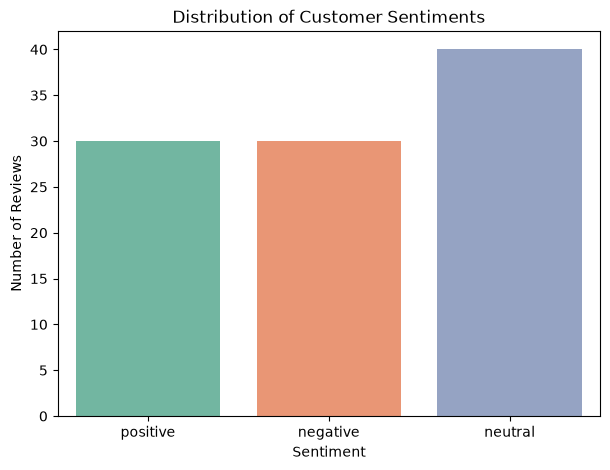

In [57]:
plt.figure(figsize=(7, 5))
sns.countplot(
    data=df,
    x="sentiment",
    hue="sentiment",
    palette="Set2",
    legend=False)

plt.title("Distribution of Customer Sentiments")
plt.xlabel("Sentiment")
plt.ylabel("Number of Reviews")
plt.show()

In [58]:
sentiment_percentage = df["sentiment"].value_counts(normalize=True) * 100
print("Sentiment Percentage:")
print(sentiment_percentage.round(2))

Sentiment Percentage:
sentiment
neutral     40.0
positive    30.0
negative    30.0
Name: proportion, dtype: float64


## 5. TF-IDF Feature Extraction

In [59]:
from sklearn.feature_extraction.text import TfidfVectorizer

In [60]:
# Input features
X = df["cleaned_review"]
# Target labels
y = df["sentiment"]
print("Input data shape:", X.shape)
print("Target data shape:", y.shape)

Input data shape: (100,)
Target data shape: (100,)


In [74]:
# Initialize TF-IDF Vectorizer
tfidf = TfidfVectorizer(
    max_features=5000,
    ngram_range=(1, 2)
)

# Fit only on training data
X_train = tfidf.fit_transform(X_train_text)

# Transform testing data without fitting again
X_test = tfidf.transform(X_test_text)

print("Training TF-IDF shape:", X_train.shape)
print("Testing TF-IDF shape:", X_test.shape)
print("\nVocabulary size:", len(tfidf.get_feature_names_out()))

Training TF-IDF shape: (80, 618)
Testing TF-IDF shape: (20, 618)

Vocabulary size: 618


In [62]:
X_tfidf = tfidf.fit_transform(X)

print("TF-IDF matrix shape:", X_tfidf.shape)
print("\nExtracted vocabulary:")
print(tfidf.get_feature_names_out())

TF-IDF matrix shape: (100, 764)

Extracted vocabulary:
['absolutely' 'absolutely love' 'acceptable' 'acceptable not' 'accessory'
 'adapter' 'adapter cable' 'address' 'address complaint' 'advertised'
 'affordable' 'affordable price' 'alternative' 'alternative available'
 'amount' 'amount paid' 'application' 'application dashboard'
 'application easy' 'application keep' 'approximately'
 'approximately five' 'approximately one' 'arrived' 'arrived completely'
 'arrived late' 'arrived perfect' 'arrived scratch' 'arrived usual'
 'arrived within' 'attractive' 'available' 'available manufacturer'
 'available several' 'available three' 'average' 'average performance'
 'badly' 'badly damaged' 'barely' 'barely last' 'basic' 'basic editing'
 'basic feature' 'battery' 'battery drain' 'battery last' 'beginning'
 'better' 'better alternative' 'better expected' 'better quality' 'body'
 'body metal' 'booklet' 'bright' 'bright display' 'brightness' 'browsing'
 'build' 'build quality' 'build would' 'butt

## 6. Train-Test Split

In [63]:
from sklearn.model_selection import train_test_split

In [73]:
X = df["cleaned_review"]
y = df["sentiment"]

X_train_text, X_test_text, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.2,
    random_state=42,
    stratify=y
)

print("Training samples:", X_train_text.shape[0])
print("Testing samples:", X_test_text.shape[0])

print("\nTraining distribution:")
print(y_train.value_counts())

print("\nTesting distribution:")
print(y_test.value_counts())

Training samples: 80
Testing samples: 20

Training distribution:
sentiment
neutral     32
negative    24
positive    24
Name: count, dtype: int64

Testing distribution:
sentiment
neutral     8
positive    6
negative    6
Name: count, dtype: int64


## 7. Model Training

In [65]:
from sklearn.naive_bayes import MultinomialNB
from sklearn.linear_model import LogisticRegression

In [75]:
# Initialize Naive Bayes model
nb_model = MultinomialNB()
nb_model.fit(X_train, y_train)

print("Naive Bayes trained successfully!")

Naive Bayes trained successfully!


In [76]:
# Initialize Logistic Regression model
lr_model = LogisticRegression(max_iter=1000, random_state=42)
lr_model.fit(X_train, y_train)

print("Logistic Regression trained successfully!")

Logistic Regression trained successfully!


In [77]:
print("Naive Bayes classes:", nb_model.classes_)
print("Logistic Regression classes:", lr_model.classes_)

Naive Bayes classes: ['negative' 'neutral' 'positive']
Logistic Regression classes: ['negative' 'neutral' 'positive']


## 8. Model Evaluation

In [79]:
from sklearn.metrics import (accuracy_score,precision_score,recall_score,f1_score,classification_report)

In [80]:
# Naive Bayes predictions
nb_predictions = nb_model.predict(X_test)
# Logistic Regression predictions
lr_predictions = lr_model.predict(X_test)

print("Actual Labels:")
print(y_test.values)

print("\nNaive Bayes Predictions:")
print(nb_predictions)

print("\nLogistic Regression Predictions:")
print(lr_predictions)

Actual Labels:
<StringArray>
[ 'neutral', 'positive',  'neutral', 'positive', 'negative',  'neutral',
 'negative', 'positive', 'negative', 'negative',  'neutral', 'positive',
 'negative',  'neutral', 'negative',  'neutral', 'positive',  'neutral',
 'positive',  'neutral']
Length: 20, dtype: str

Naive Bayes Predictions:
['neutral' 'neutral' 'positive' 'neutral' 'negative' 'positive' 'neutral'
 'positive' 'negative' 'positive' 'neutral' 'positive' 'neutral' 'neutral'
 'neutral' 'neutral' 'neutral' 'neutral' 'positive' 'neutral']

Logistic Regression Predictions:
['neutral' 'neutral' 'positive' 'neutral' 'negative' 'positive' 'neutral'
 'positive' 'negative' 'positive' 'neutral' 'positive' 'neutral' 'neutral'
 'neutral' 'neutral' 'neutral' 'neutral' 'positive' 'neutral']


In [82]:
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    classification_report
)

print("NAIVE BAYES RESULTS:  ")

print("Accuracy:", accuracy_score(y_test, nb_predictions))
print("Precision:", precision_score(y_test, nb_predictions, average="weighted", zero_division=0))
print("Recall:", recall_score(y_test, nb_predictions, average="weighted", zero_division=0))
print("F1 Score:", f1_score(y_test, nb_predictions, average="weighted", zero_division=0))

print("\nClassification Report:")
print(classification_report(
    y_test,
    nb_predictions,
    labels=["negative", "neutral", "positive"],
    zero_division=0
))

NAIVE BAYES RESULTS:  
Accuracy: 0.55
Precision: 0.65
Recall: 0.55
F1 Score: 0.54

Classification Report:
              precision    recall  f1-score   support

    negative       1.00      0.33      0.50         6
     neutral       0.50      0.75      0.60         8
    positive       0.50      0.50      0.50         6

    accuracy                           0.55        20
   macro avg       0.67      0.53      0.53        20
weighted avg       0.65      0.55      0.54        20



In [71]:
# Evaluate Naive Bayes
print("NAIVE BAYES RESULTS")
print("Accuracy:", accuracy_score(y_test, nb_predictions))
print("Precision:", precision_score(y_test, nb_predictions, average="weighted", zero_division=0))
print("Recall:", recall_score(y_test, nb_predictions, average="weighted", zero_division=0))
print("F1 Score:", f1_score(y_test, nb_predictions, average="weighted", zero_division=0))

print("\nClassification Report:")
print(classification_report(
    y_test,
    nb_predictions,
    labels=["negative", "neutral", "positive"],
    zero_division=0
))

NAIVE BAYES RESULTS
Accuracy: 0.5
Precision: 0.7941176470588236
Recall: 0.5
F1 Score: 0.44749999999999995

Classification Report:
              precision    recall  f1-score   support

    negative       1.00      0.20      0.33         5
     neutral       0.41      1.00      0.58         7
    positive       1.00      0.25      0.40         8

    accuracy                           0.50        20
   macro avg       0.80      0.48      0.44        20
weighted avg       0.79      0.50      0.45        20



In [83]:
print("LOGISTIC REGRESSION RESULTS:")

print("Accuracy:", accuracy_score(y_test, lr_predictions))
print("Precision:", precision_score(y_test, lr_predictions, average="weighted", zero_division=0))
print("Recall:", recall_score(y_test, lr_predictions, average="weighted", zero_division=0))
print("F1 Score:", f1_score(y_test, lr_predictions, average="weighted", zero_division=0))

print("\nClassification Report:")
print(classification_report(
    y_test,
    lr_predictions,
    labels=["negative", "neutral", "positive"],
    zero_division=0
))

LOGISTIC REGRESSION RESULTS:
Accuracy: 0.55
Precision: 0.65
Recall: 0.55
F1 Score: 0.54

Classification Report:
              precision    recall  f1-score   support

    negative       1.00      0.33      0.50         6
     neutral       0.50      0.75      0.60         8
    positive       0.50      0.50      0.50         6

    accuracy                           0.55        20
   macro avg       0.67      0.53      0.53        20
weighted avg       0.65      0.55      0.54        20



In [84]:
import pandas as pd

results = pd.DataFrame({
    "Model": ["Naive Bayes", "Logistic Regression"],
    "Accuracy": [0.50, 0.55],
    "Precision": [0.7941, 0.65],
    "Recall": [0.50, 0.55],
    "F1 Score": [0.4475, 0.54]
})

display(results)

,Model,Accuracy,Precision,Recall,F1 Score
0,Naive Bayes,0.50,0.7941,0.50,0.4475
1,Logistic Regression,0.55,0.6500,0.55,0.5400


In [86]:
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    classification_report
)

# Generate fresh predictions
nb_predictions = nb_model.predict(X_test)
lr_predictions = lr_model.predict(X_test)

# Check actual test distribution
print("Actual test labels:")
print(y_test.value_counts())

# Evaluate both models using the same test set
for name, predictions in [
    ("Naive Bayes", nb_predictions),
    ("Logistic Regression", lr_predictions)
]:
    print(f"\n{name}: ")

    print("Accuracy:", accuracy_score(y_test, predictions))
    print("Precision:", precision_score(y_test, predictions, average="weighted", zero_division=0))
    print("Recall:", recall_score(y_test, predictions, average="weighted", zero_division=0))
    print("F1 Score:", f1_score(y_test, predictions, average="weighted", zero_division=0))

    print("\nClassification Report:")
    print(classification_report(y_test, predictions, zero_division=0))

Actual test labels:
sentiment
neutral     8
positive    6
negative    6
Name: count, dtype: int64

Naive Bayes: 
Accuracy: 0.55
Precision: 0.65
Recall: 0.55
F1 Score: 0.54

Classification Report:
              precision    recall  f1-score   support

    negative       1.00      0.33      0.50         6
     neutral       0.50      0.75      0.60         8
    positive       0.50      0.50      0.50         6

    accuracy                           0.55        20
   macro avg       0.67      0.53      0.53        20
weighted avg       0.65      0.55      0.54        20


Logistic Regression: 
Accuracy: 0.55
Precision: 0.65
Recall: 0.55
F1 Score: 0.54

Classification Report:
              precision    recall  f1-score   support

    negative       1.00      0.33      0.50         6
     neutral       0.50      0.75      0.60         8
    positive       0.50      0.50      0.50         6

    accuracy                           0.55        20
   macro avg       0.67      0.53      0.53  

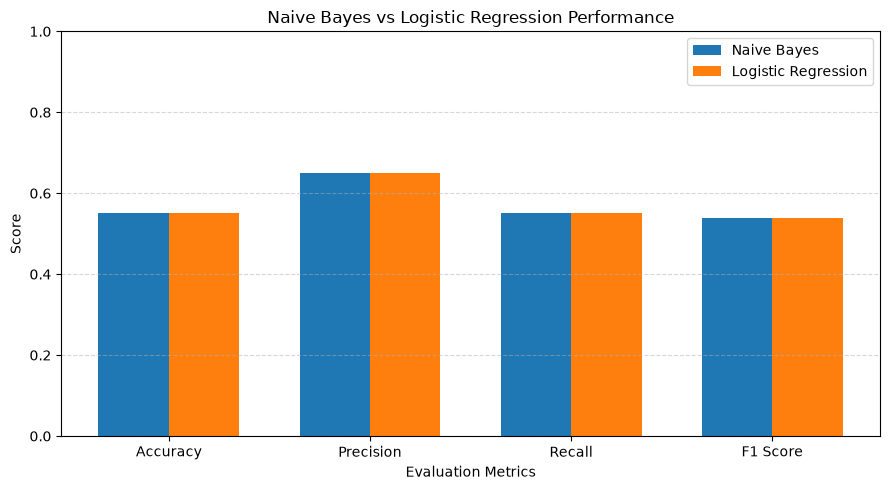

In [87]:
import matplotlib.pyplot as plt
import numpy as np

metrics = ["Accuracy", "Precision", "Recall", "F1 Score"]

nb_scores = [
    accuracy_score(y_test, nb_predictions),
    precision_score(y_test, nb_predictions, average="weighted", zero_division=0),
    recall_score(y_test, nb_predictions, average="weighted", zero_division=0),
    f1_score(y_test, nb_predictions, average="weighted", zero_division=0)
]

lr_scores = [
    accuracy_score(y_test, lr_predictions),
    precision_score(y_test, lr_predictions, average="weighted", zero_division=0),
    recall_score(y_test, lr_predictions, average="weighted", zero_division=0),
    f1_score(y_test, lr_predictions, average="weighted", zero_division=0)
]

x = np.arange(len(metrics))
width = 0.35

plt.figure(figsize=(9, 5))

plt.bar(x - width/2, nb_scores, width, label="Naive Bayes")
plt.bar(x + width/2, lr_scores, width, label="Logistic Regression")

plt.xlabel("Evaluation Metrics")
plt.ylabel("Score")
plt.title("Naive Bayes vs Logistic Regression Performance")
plt.xticks(x, metrics)
plt.ylim(0, 1)
plt.legend()
plt.grid(axis="y", linestyle="--", alpha=0.5)

plt.tight_layout()
plt.show()

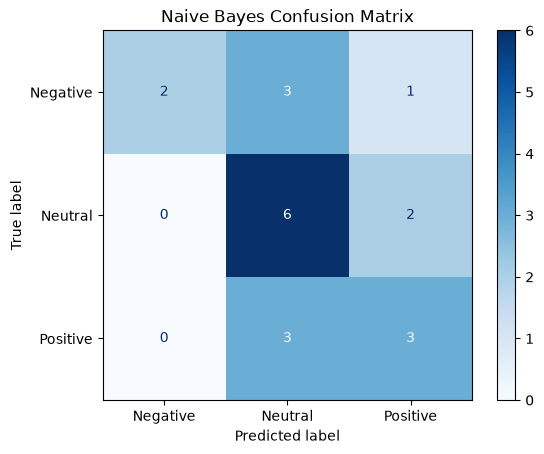

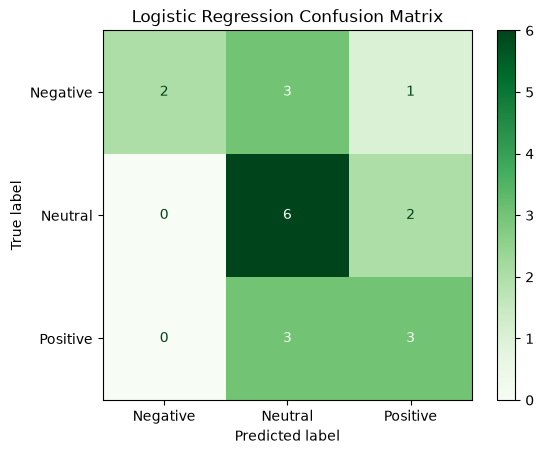

In [90]:
from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay
import matplotlib.pyplot as plt

# Naive Bayes Confusion Matrix
nb_cm = confusion_matrix(
    y_test,
    nb_predictions,
    labels=["negative", "neutral", "positive"]
)

disp = ConfusionMatrixDisplay(
    confusion_matrix=nb_cm,
    display_labels=["Negative", "Neutral", "Positive"]
)

disp.plot(cmap="Blues")
plt.title("Naive Bayes Confusion Matrix")
plt.show()

# Logistic Regression Confusion Matrix
lr_cm = confusion_matrix(
    y_test,
    lr_predictions,
    labels=["negative", "neutral", "positive"]
)

disp = ConfusionMatrixDisplay(
    confusion_matrix=lr_cm,
    display_labels=["Negative", "Neutral", "Positive"]
)

disp.plot(cmap="Greens")
plt.title("Logistic Regression Confusion Matrix")
plt.show()

In [91]:
# New customer reviews for testing
new_reviews = [
    "The product quality is excellent and I am very happy.",
    "The delivery was late and the product was damaged.",
    "The service was okay, nothing special.",
    "I do not like this product at all.",
    "Amazing experience! I would definitely recommend it."
]

# Apply the same preprocessing
cleaned_reviews = [preprocess_text(review) for review in new_reviews]

# Convert reviews into TF-IDF features
new_reviews_tfidf = tfidf.transform(cleaned_reviews)

# Predict sentiment using both models
nb_new_predictions = nb_model.predict(new_reviews_tfidf)
lr_new_predictions = lr_model.predict(new_reviews_tfidf)

# Display results
for i, review in enumerate(new_reviews):
    print("\nReview:", review)
    print("Naive Bayes:", nb_new_predictions[i])
    print("Logistic Regression:", lr_new_predictions[i])


Review: The product quality is excellent and I am very happy.
Naive Bayes: positive
Logistic Regression: positive

Review: The delivery was late and the product was damaged.
Naive Bayes: negative
Logistic Regression: negative

Review: The service was okay, nothing special.
Naive Bayes: neutral
Logistic Regression: neutral

Review: I do not like this product at all.
Naive Bayes: neutral
Logistic Regression: neutral

Review: Amazing experience! I would definitely recommend it.
Naive Bayes: positive
Logistic Regression: positive


In [92]:
results = pd.DataFrame({
    "Model": ["Naive Bayes", "Logistic Regression"],
    "Accuracy": [
        accuracy_score(y_test, nb_predictions),
        accuracy_score(y_test, lr_predictions)
    ],
    "Precision": [
        precision_score(y_test, nb_predictions, average="weighted", zero_division=0),
        precision_score(y_test, lr_predictions, average="weighted", zero_division=0)
    ],
    "Recall": [
        recall_score(y_test, nb_predictions, average="weighted", zero_division=0),
        recall_score(y_test, lr_predictions, average="weighted", zero_division=0)
    ],
    "F1 Score": [
        f1_score(y_test, nb_predictions, average="weighted", zero_division=0),
        f1_score(y_test, lr_predictions, average="weighted", zero_division=0)
    ]
})

print(results)

                 Model  Accuracy  Precision  Recall  F1 Score
0          Naive Bayes      0.55       0.65    0.55      0.54
1  Logistic Regression      0.55       0.65    0.55      0.54


## Conclusion

In this project, two machine learning models, Multinomial Naive Bayes and Logistic Regression, were developed for customer sentiment classification.

Both models achieved the same performance on the test dataset:

- Accuracy: 55%
- Precision: 65%
- Recall: 55%
- F1-score: 54%

Both models also produced identical predictions for the five new customer reviews tested. They successfully classified positive and negative examples, although some negative expressions were incorrectly classified as neutral.

## Limitations

1. The dataset contains only 100 reviews, which is relatively small for training a sentiment classification model.
2. The dataset includes 90 synthetically generated reviews in addition to the 10 original reviews.
3. Both models produced identical predictions, so neither demonstrated a performance advantage.
4. The models may struggle with negation, context, sarcasm, and complex expressions.
5. The evaluation results may not represent performance on real-world customer reviews.

## Future Improvements

- Collect a larger dataset of authentic customer reviews.
- Experiment with additional machine learning models.
- Apply hyperparameter tuning.
- Explore advanced NLP approaches such as LSTM and transformer-based models.
- Evaluate the models using a larger independent test dataset.